# UFC Fight Analytics — Exploration

EDA and model diagnostics on top of the `ufc` package. All pipeline logic
lives in `src/ufc/`; this notebook only visualizes.

- Refresh data: `just scrape`
- Rebuild features + model: `just train`

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from ufc import config
from ufc.features.build import load_raw
from ufc.features.cleaning import clean_fight_data

sns.set_theme(style="whitegrid")

fighters, fights, fight_stats = load_raw(config.RAW_DIR)
fights_clean, fight_stats_clean = clean_fight_data(fights, fight_stats)
print(f"fighters: {len(fighters)}  fights: {len(fights)} "
      f"({len(fights_clean)} with decisive W/L)  stat rows: {len(fight_stats)}")

fighters: 2693  fights: 8758 (8559 with decisive W/L)  stat rows: 17474


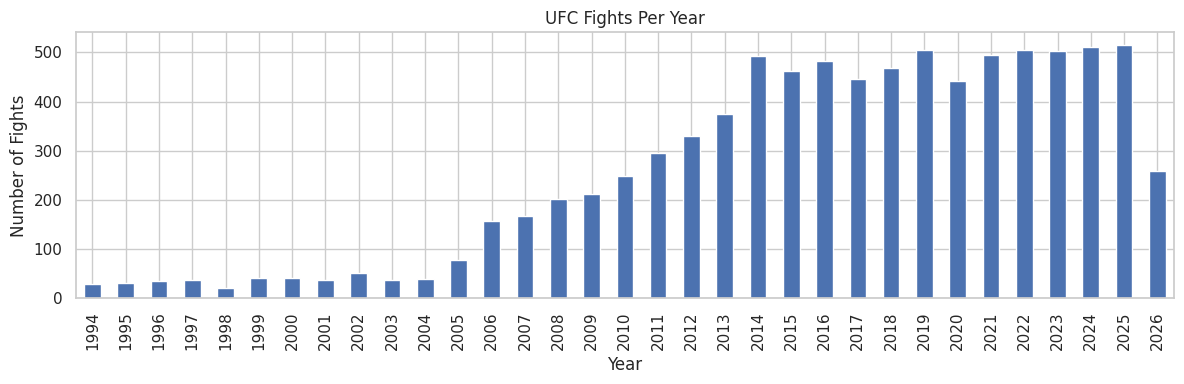

In [2]:
fig, ax = plt.subplots(figsize=(12, 4))
fights_clean["event_date"].dt.year.value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("UFC Fights Per Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Fights")
plt.tight_layout()

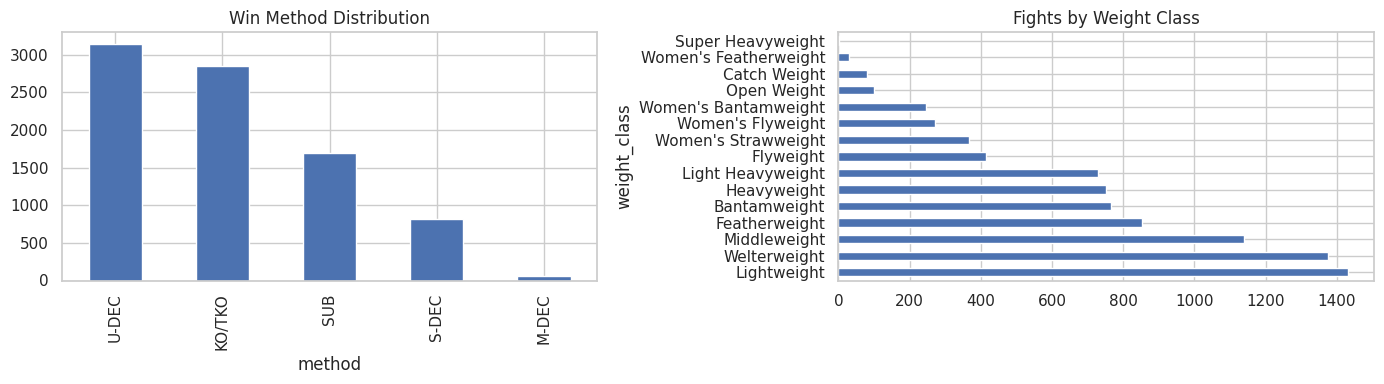

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fights_clean["method"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Win Method Distribution")
fights_clean["weight_class"].value_counts().plot(kind="barh", ax=axes[1])
axes[1].set_title("Fights by Weight Class")
plt.tight_layout()

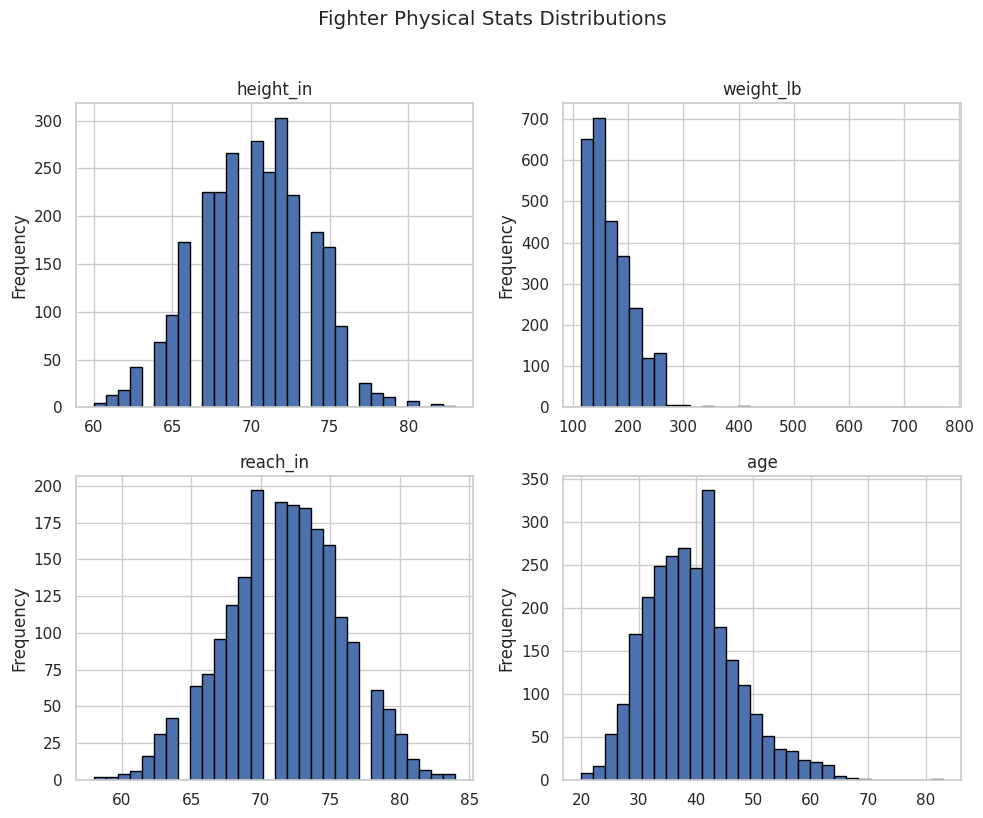

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.flat, ["height_in", "weight_lb", "reach_in", "age"]):
    fighters[col].dropna().plot(kind="hist", bins=30, ax=ax, edgecolor="black")
    ax.set_title(col)
plt.suptitle("Fighter Physical Stats Distributions", y=1.02)
plt.tight_layout()

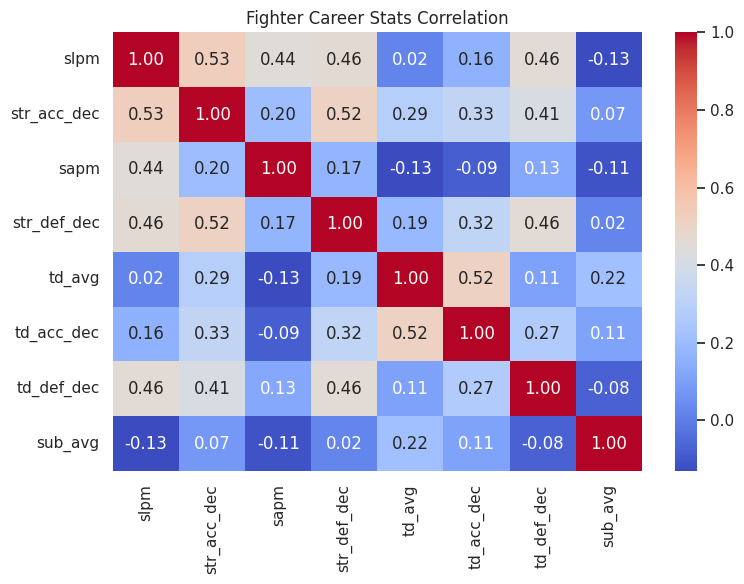

In [5]:
career_stats = ["slpm", "str_acc_dec", "sapm", "str_def_dec",
                "td_avg", "td_acc_dec", "td_def_dec", "sub_avg"]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(fighters[career_stats].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", ax=ax)
ax.set_title("Fighter Career Stats Correlation")
plt.tight_layout()

## Current model diagnostics

Evaluates the saved bundle (`models/current/`) on the held-out test split.
Run `just prepare` first if `data/prepared/` is missing.

model: logistic_regression (version 2026-07-08T21-13-01)
test accuracy: 0.708
test AUC: 0.781


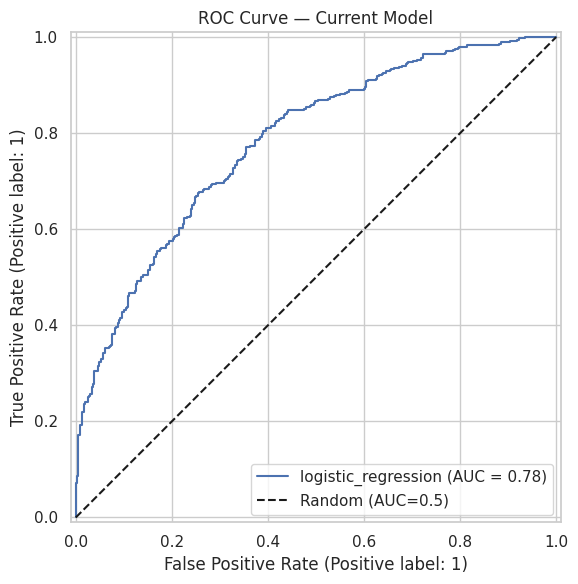

In [6]:
from sklearn.metrics import RocCurveDisplay, accuracy_score, roc_auc_score

from ufc.modeling.registry import load_model_bundle

bundle = load_model_bundle()
test = pd.read_csv(config.PREPARED_DIR / "test.csv")
X_test, y_test = test[bundle.feature_cols], test["target"]
y_prob = bundle.pipeline.predict_proba(X_test)[:, 1]

print(f"model: {bundle.metadata['model_name']} (version {bundle.model_version})")
print(f"test accuracy: {accuracy_score(y_test, y_prob > 0.5):.3f}")
print(f"test AUC: {roc_auc_score(y_test, y_prob):.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, y_prob,
                                 name=bundle.metadata["model_name"], ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC=0.5)")
ax.set_title("ROC Curve — Current Model")
ax.legend()
plt.tight_layout()

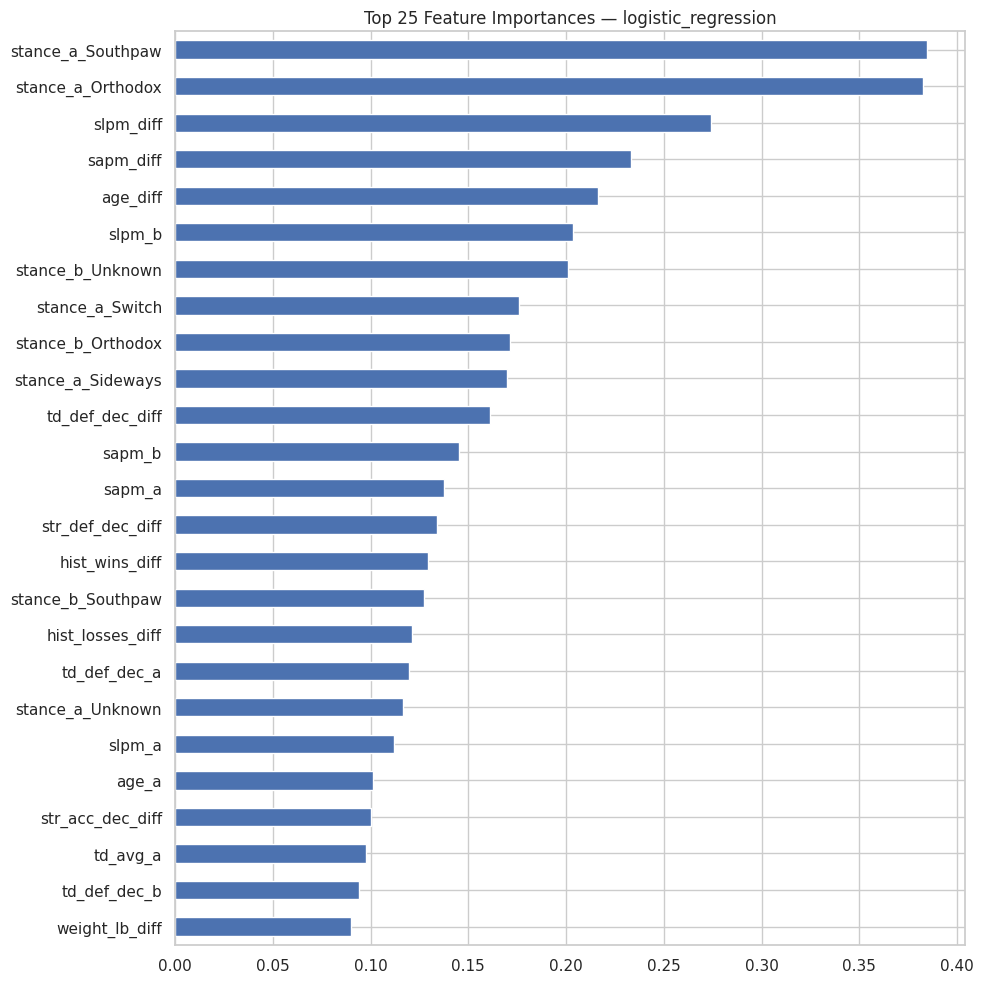

In [7]:
model = bundle.pipeline.named_steps["model"]
if hasattr(model, "feature_importances_"):
    importances = model.feature_importances_
else:
    import numpy as np
    importances = np.abs(model.coef_[0])

feat_imp = pd.Series(importances, index=bundle.feature_cols).sort_values()
fig, ax = plt.subplots(figsize=(10, 10))
feat_imp.tail(25).plot(kind="barh", ax=ax)
ax.set_title(f"Top 25 Feature Importances — {bundle.metadata['model_name']}")
plt.tight_layout()